# 员工离职风险预测 · 线性回归分析全流程

本 notebook 用 **Anaconda + Jupyter** 完成一套完整的数据分析与建模流程，
重点落在**线性回归**上，同时给出对比模型。

## 流程

| 步骤 | 内容 |
|---|---|
| 1 | 环境与数据加载 |
| 2 | 数据整理（质量体检 / 清洗） |
| 3 | 探索性分析 EDA |
| 4 | 特征工程 |
| 5 | **数据划分：训练 / 验证 / 测试 三段式** |
| 6 | **线性回归 A：预测月收入**（含 OLS 系数、p 值、VIF、残差诊断） |
| 7 | **线性回归 B：线性概率模型预测离职** |
| 8 | 逻辑回归对照 |
| 9 | 结果对比与结论 |

## 关于验证集

- **训练集**：拟合模型参数
- **验证集**：选模型 + 标定决策阈值
- **测试集**：全程封存，最后只用一次，反映真实泛化能力

> 若省掉验证集、直接用测试集调阈值，测试指标会偏乐观 —— 这是常见但隐蔽的偏差。

## 1. 环境与数据加载

In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             roc_auc_score, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix,
                             roc_curve, classification_report)

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

warnings.filterwarnings("ignore")
np.random.seed(42)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("statsmodels :", sm.__version__)

Python      : 3.14.6
pandas      : 3.0.3
scikit-learn: 1.9.0
statsmodels : 0.14.6


In [2]:
# 中文字体（macOS 上 SimHei 不存在，会导致中文显示为方框）
CJK = ["PingFang SC", "Arial Unicode MS", "Heiti SC", "Hiragino Sans GB", "STHeiti"]
avail = {f.name for f in font_manager.fontManager.ttflist}
CN = next((f for f in CJK if f in avail), "Arial Unicode MS")
plt.rcParams["font.sans-serif"] = [CN] + CJK
plt.rcParams["axes.unicode_minus"] = False
sns.set_theme(style="whitegrid", font=CN)
print("使用中文字体:", CN)

使用中文字体: PingFang SC


In [3]:
# 定位项目根目录（notebook 放在 notebooks/ 下）
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA, FIG = ROOT / "data", ROOT / "output" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

RAW = DATA / "hr_merged.csv"
if not RAW.exists():
    RAW = DATA / "ibm_hr_attrition_raw.csv"

df = pd.read_csv(RAW, encoding="utf-8-sig")
print("文件:", RAW.name, "| 形状:", df.shape)
df.head()

文件: hr_merged.csv | 形状: (3000, 33)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,_source
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Yes,11,3,1,0,8,0,1,6,4,0,5,real
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,No,23,4,4,1,10,3,3,10,7,1,7,real
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Yes,15,3,2,0,7,3,3,0,0,0,0,real
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Yes,11,3,3,0,8,3,3,8,7,3,0,real
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,No,12,3,4,1,6,3,3,2,2,2,2,real


## 2. 数据整理

先做一次"数据体检"：缺失、重复、常量列、异常值、目标分布。
这一步决定了后面能不能直接建模。

In [4]:
print("=" * 60)
print("数据质量体检")
print("=" * 60)

print(f"\n行数 x 列数 : {df.shape[0]} x {df.shape[1]}")

miss = df.isna().sum()
print(f"缺失值列数  : {(miss > 0).sum()}  ({'无缺失' if (miss > 0).sum() == 0 else ''})")

print(f"完全重复行  : {df.duplicated().sum()}")

const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print(f"单值常量列  : {const_cols if const_cols else '无'}")

print("\n各列类型分布:")
print(df.dtypes.value_counts().to_string())

数据质量体检

行数 x 列数 : 3000 x 33
缺失值列数  : 0  (无缺失)
完全重复行  : 0
单值常量列  : 无

各列类型分布:
int64    24
str       9


In [5]:
# 目标变量
print("Attrition 分布:")
vc = df["Attrition"].value_counts()
for k, v in vc.items():
    print(f"  {k:<4} {v:>5}  ({v/len(df):.2%})")

rate_all = df["Attrition"].eq("Yes").mean()
print(f"\n整体离职率: {rate_all:.2%}")

# 区分真实/模拟数据
if "_source" in df.columns:
    print("\n数据来源:")
    print(df["_source"].value_counts().to_string())
    real = df[df["_source"] == "real"].reset_index(drop=True)
    print(f"\n=> 后续建模只用真实数据 {len(real)} 条（模拟数据仅用于可视化）")
else:
    real = df.copy()

rate = real["Attrition"].eq("Yes").mean()
print(f"真实数据离职率: {rate:.2%}   不平衡比 1:{(1-rate)/rate:.2f}")

Attrition 分布:
  No    2516  (83.87%)
  Yes    484  (16.13%)

整体离职率: 16.13%

数据来源:
_source
simulated    1530
real         1470

=> 后续建模只用真实数据 1470 条（模拟数据仅用于可视化）
真实数据离职率: 16.12%   不平衡比 1:5.20


In [6]:
# 清洗：删掉无信息量的常数列与 ID 列
DROP = [c for c in ["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"]
        if c in real.columns]
real = real.drop(columns=DROP)
print("已删除列:", DROP)

# 异常值检查（用 IQR 法标记，不直接删——业务上可能是真实的极端高薪）
def outlier_count(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

num_cols_all = real.select_dtypes(include=[np.number]).columns.tolist()
out = pd.Series({c: outlier_count(real[c]) for c in num_cols_all})
out = out[out > 0].sort_values(ascending=False)
print("\n存在离群值的列（IQR 法，仅标记不删除）:")
for k, v in out.items():
    print(f"  {k:<26} {v:>4} 条 ({v/len(real):.1%})")

已删除列: ['EmployeeNumber']

存在离群值的列（IQR 法，仅标记不删除）:
  TrainingTimesLastYear       238 条 (16.2%)
  PerformanceRating           226 条 (15.4%)
  MonthlyIncome               114 条 (7.8%)
  YearsSinceLastPromotion     107 条 (7.3%)
  YearsAtCompany              104 条 (7.1%)
  StockOptionLevel             85 条 (5.8%)
  TotalWorkingYears            63 条 (4.3%)
  NumCompaniesWorked           52 条 (3.5%)
  YearsInCurrentRole           21 条 (1.4%)
  YearsWithCurrManager         14 条 (1.0%)


## 3. 探索性分析（EDA）

看三件事：目标不平衡程度、哪些因素和离职最相关、关键业务切分下的离职率差异。

findfont: Failed to find font weight bold, now using 600.


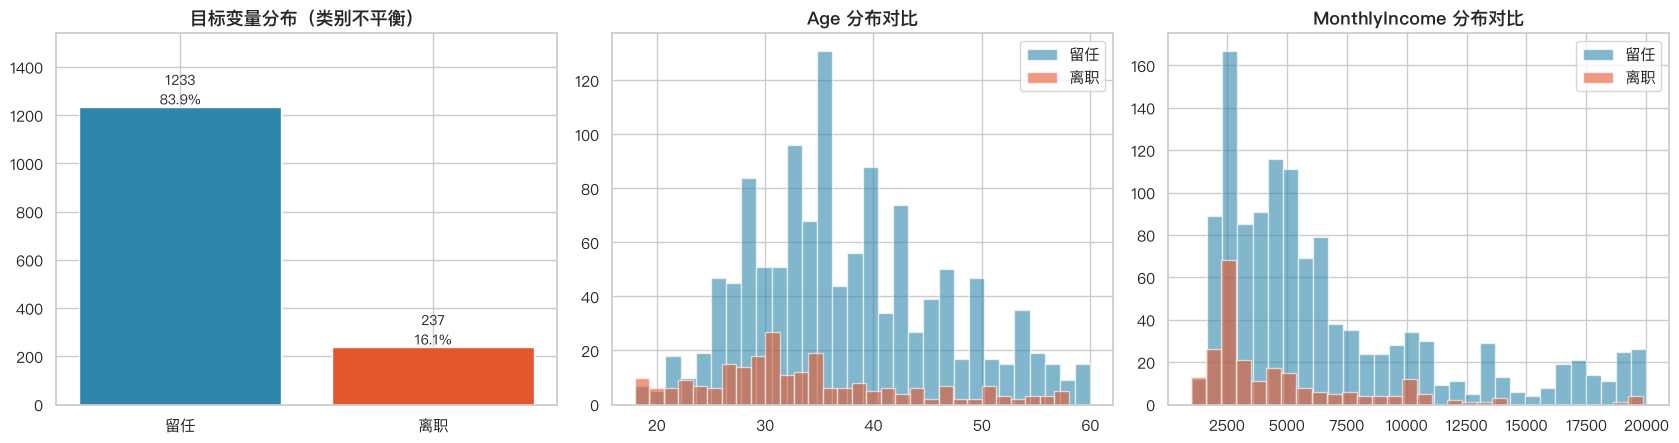

In [7]:
def safe_hist(ax, data, bins=30, **kw):
    '''按数据实际取值范围自动收缩 bins 数量。

    离散整数特征（如 PerformanceRating 只有 3/4 两个取值）直接给 30 个 bin
    会让 numpy 无法构造等宽区间而报 ValueError，这里统一兜住。
    '''
    d = np.asarray(data, dtype=float)
    d = d[np.isfinite(d)]
    if d.size == 0:
        return
    lo, hi = d.min(), d.max()
    span = hi - lo
    if span <= 0:
        ax.axvline(lo, **{k: v for k, v in kw.items() if k in ("color", "alpha")})
        return
    # 用「整数取值个数」和「30」中较小者作为 bin 数
    n_unique = np.unique(d).size
    nb = int(min(bins, max(1, min(n_unique, span + 1 if span < 200 else bins))))
    ax.hist(d, bins=nb, **kw)


fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (1) 目标分布
cnt = real["Attrition"].value_counts().reindex(["No", "Yes"])
axes[0].bar(["留任", "离职"], cnt.values, color=["#2E86AB", "#E4572E"])
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 12, f"{v}\n{v/len(real):.1%}", ha="center", fontsize=10)
axes[0].set_title("目标变量分布（类别不平衡）", fontsize=13, fontweight="bold")
axes[0].set_ylim(0, cnt.max() * 1.25)

# (2) 关键数值特征分布对比
for col, ax in [("Age", axes[1]), ("MonthlyIncome", axes[2])]:
    for lab, c in [("No", "#2E86AB"), ("Yes", "#E4572E")]:
        safe_hist(ax, real.loc[real.Attrition == lab, col], bins=30, alpha=.6,
                  label=f"{'留任' if lab=='No' else '离职'}", color=c)
    ax.set_title(f"{col} 分布对比", fontsize=13, fontweight="bold")
    ax.legend()

plt.tight_layout()
plt.savefig(FIG / "nb_01_目标与分布.png", dpi=120, bbox_inches="tight")
plt.show()

与离职相关性 Top 15:
TotalWorkingYears         -0.1711
JobLevel                  -0.1691
YearsInCurrentRole        -0.1605
MonthlyIncome             -0.1598
Age                       -0.1592
YearsWithCurrManager      -0.1562
StockOptionLevel          -0.1371
YearsAtCompany            -0.1344
JobInvolvement            -0.1300
JobSatisfaction           -0.1035
EnvironmentSatisfaction   -0.1034
DistanceFromHome           0.0779
WorkLifeBalance           -0.0639
TrainingTimesLastYear     -0.0595
DailyRate                 -0.0567


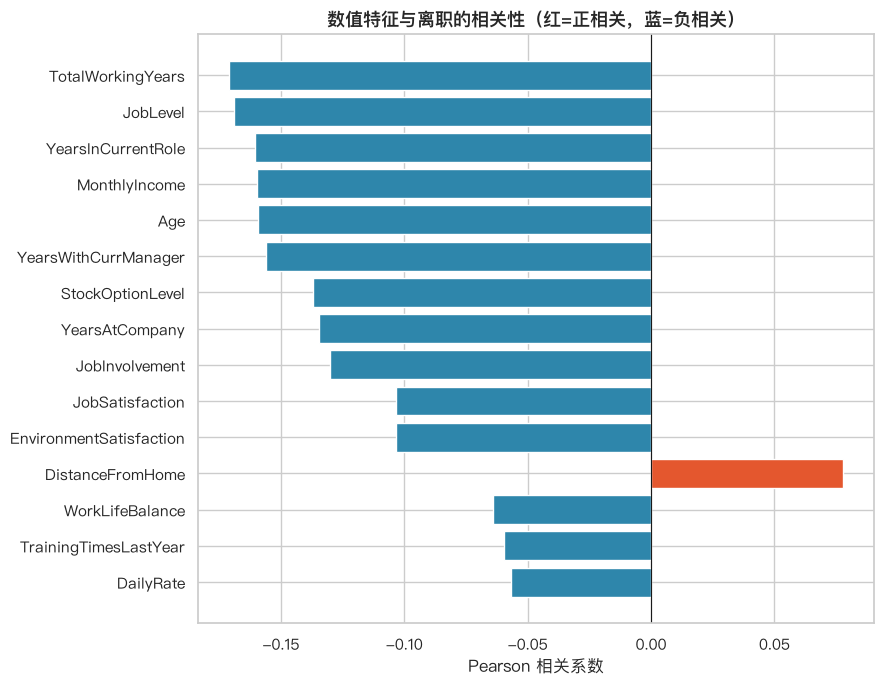

In [8]:
# 数值特征与离职的相关性
num_cols = real.select_dtypes(include=[np.number]).columns.tolist()
corr_df = real[num_cols].copy()
corr_df["离职"] = real["Attrition"].eq("Yes").astype(int)
corr = corr_df.corr()["离职"].drop("离职").sort_values(key=abs, ascending=False)

print("与离职相关性 Top 15:")
print(corr.head(15).round(4).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
top = corr.head(15)[::-1]
ax.barh(top.index, top.values,
        color=["#E4572E" if v > 0 else "#2E86AB" for v in top.values])
ax.axvline(0, color="k", lw=.8)
ax.set_title("数值特征与离职的相关性（红=正相关，蓝=负相关）",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Pearson 相关系数")
plt.tight_layout()
plt.savefig(FIG / "nb_02_相关性.png", dpi=120, bbox_inches="tight")
plt.show()

In [9]:
# 类别特征 × 离职率
CAT_ALL = real.select_dtypes(include=["object"]).columns.tolist()
CAT_ALL = [c for c in CAT_ALL if c != "_source"]

for c in CAT_ALL:
    if real[c].nunique() > 10:
        continue
    g = real.groupby(c)["Attrition"].agg(人数="size",
                                       离职数=lambda s: s.eq("Yes").sum())
    g["离职率"] = g["离职数"] / g["人数"]
    g = g.sort_values("离职率", ascending=False)
    print(f"\n[{c}]")
    print(g.assign(离职率=g["离职率"].map(lambda v: f"{v:.1%}")).to_string())


[Attrition]
             人数  离职数     离职率
Attrition                   
Yes         237  237  100.0%
No         1233    0    0.0%

[BusinessTravel]
                     人数  离职数    离职率
BusinessTravel                     
Travel_Frequently   277   69  24.9%
Travel_Rarely      1043  156  15.0%
Non-Travel          150   12   8.0%

[Department]
                         人数  离职数    离职率
Department                             
Sales                   446   92  20.6%
Human Resources          63   12  19.0%
Research & Development  961  133  13.8%

[EducationField]
                   人数  离职数    离职率
EducationField                   
Human Resources    27    7  25.9%
Technical Degree  132   32  24.2%
Marketing         159   35  22.0%
Life Sciences     606   89  14.7%
Medical           464   63  13.6%
Other              82   11  13.4%

[Gender]
         人数  离职数    离职率
Gender                 
Male    882  150  17.0%
Female  588   87  14.8%

[JobRole]
                            人数  离职数    离职率
JobRole  

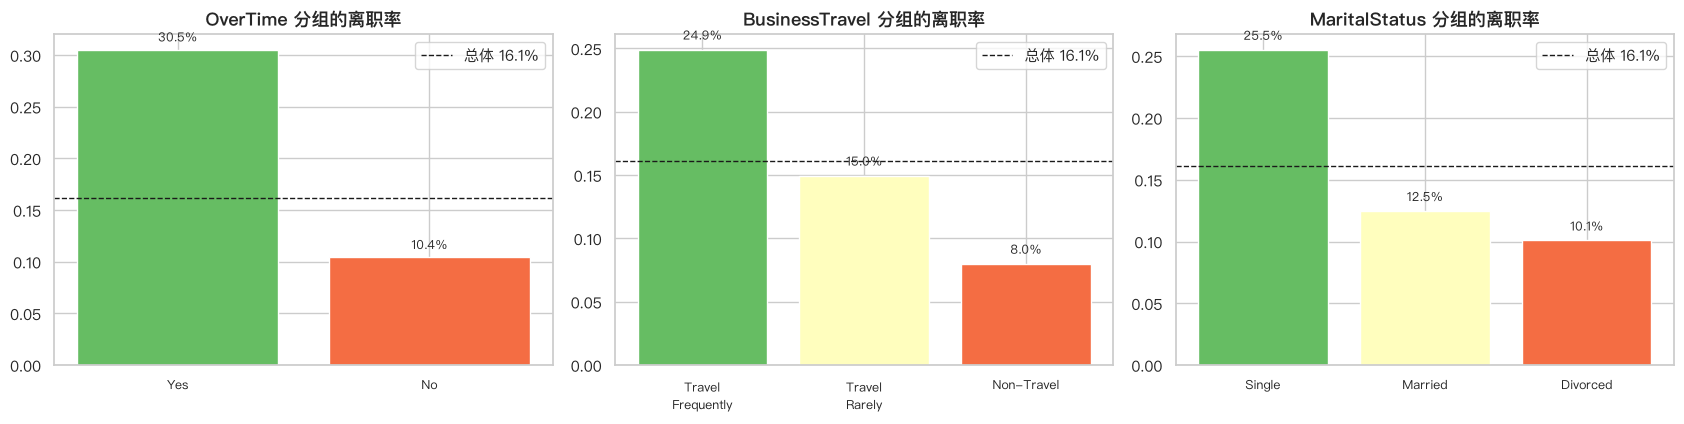

In [10]:
# 业务上最关键的切分：加班 / 出差频率
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))

for ax, col, order in [
    (axes[0], "OverTime", ["No", "Yes"]),
    (axes[1], "BusinessTravel", None),
    (axes[2], "MaritalStatus", None),
]:
    g = real.groupby(col)["Attrition"].apply(lambda s: s.eq("Yes").mean())
    if order:
        g = g.reindex(order)
    g = g.sort_values(ascending=False)
    ax.bar(range(len(g)), g.values,
           color=plt.cm.RdYlGn_r(np.linspace(.2, .8, len(g))))
    ax.set_xticks(range(len(g)))
    ax.set_xticklabels([str(i).replace("_", "\n") for i in g.index], fontsize=9)
    ax.axhline(rate, ls="--", color="k", lw=1, label=f"总体 {rate:.1%}")
    ax.set_title(f"{col} 分组的离职率", fontsize=13, fontweight="bold")
    ax.legend()
    for i, v in enumerate(g.values):
        ax.text(i, v + .008, f"{v:.1%}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(FIG / "nb_03_分类别离职率.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. 特征工程

在原始字段上构造 7 个业务含义明确的派生特征。
全部是比值/差值运算，**不含标签信息，因此不存在泄漏**。

In [11]:
def engineer(d):
    d = d.copy()
    eps = 1e-6
    d["IncomePerLevel"]    = d["MonthlyIncome"] / (d["JobLevel"] * 5000.0 + eps)
    d["TenureRatio"]       = d["YearsAtCompany"] / (d["TotalWorkingYears"] + 1.0)
    d["PromotionGap"]      = d["YearsSinceLastPromotion"] / (d["YearsAtCompany"] + 1.0)
    d["ManagerStability"]  = d["YearsWithCurrManager"] / (d["YearsAtCompany"] + 1.0)
    d["SatisfactionScore"] = (d["JobSatisfaction"] + d["EnvironmentSatisfaction"]
                              + d["RelationshipSatisfaction"] + d["WorkLifeBalance"]) / 4.0
    d["CareerStagnation"]  = (d["YearsSinceLastPromotion"] / (d["YearsInCurrentRole"] + 1.0)) \
                             * (1.0 - d["JobInvolvement"] / 4.0)
    d["CompanyHopRate"]    = d["TotalWorkingYears"] / (d["NumCompaniesWorked"] + 1.0)
    return d

DERIVED = ["IncomePerLevel", "TenureRatio", "PromotionGap", "ManagerStability",
           "SatisfactionScore", "CareerStagnation", "CompanyHopRate"]

real = engineer(real)
print("派生特征已生成:")
desc = real[DERIVED].describe().T[["mean", "std", "min", "max"]].round(3)
print(desc.to_string())

派生特征已生成:
                    mean    std    min     max
IncomePerLevel     0.595  0.154  0.202   1.000
TenureRatio        0.582  0.284  0.000   0.976
PromotionGap       0.236  0.269  0.000   0.917
ManagerStability   0.466  0.277  0.000   0.895
SatisfactionScore  2.731  0.506  1.000   4.000
CareerStagnation   0.127  0.252  0.000   3.500
CompanyHopRate     4.193  4.036  0.000  38.000


In [12]:
NUMERIC = real.select_dtypes(include=[np.number]).columns.tolist()
NUMERIC = [c for c in NUMERIC if c not in ["Attrition", "EmployeeNumber", "y"]]

# 关键：必须把目标列 Attrition 排除在类别特征之外，否则目标泄漏，
# 模型会直接读到答案，AUC 虚高到 1.0。
TARGET_COL = "Attrition"
CATEGORICAL = [c for c in real.select_dtypes(include=["object"]).columns
               if c not in ("_source", TARGET_COL)]

assert TARGET_COL not in CATEGORICAL, "目标列不得进入特征"
assert TARGET_COL not in NUMERIC, "目标列不得进入特征"

real["y"] = real[TARGET_COL].eq("Yes").astype(int)

print(f"数值特征 {len(NUMERIC)} 个:")
print("  ", ", ".join(NUMERIC))
print(f"\n类别特征 {len(CATEGORICAL)} 个:")
print("  ", ", ".join(CATEGORICAL))

# 泄漏自检：目标列绝不能出现在特征里
leak = [c for c in NUMERIC + CATEGORICAL if c in (TARGET_COL, "y")]
assert not leak, f"目标泄漏! 以下列不应作为特征: {leak}"
print(f"\n[自检] 目标列 '{TARGET_COL}' 已排除，无目标泄漏 ✓")

# 再查一遍：有没有某个特征与目标的相关性接近 1（可能泄漏）
_y = real["y"]
suspect = []
for c in NUMERIC:
    r = abs(np.corrcoef(real[c].fillna(real[c].median()), _y)[0, 1])
    if r > 0.95:
        suspect.append((c, r))
print(f"[自检] 与目标 |r|>0.95 的可疑特征: {suspect if suspect else '无 ✓'}")

数值特征 30 个:
   Age, DailyRate, DistanceFromHome, Education, EnvironmentSatisfaction, HourlyRate, JobInvolvement, JobLevel, JobSatisfaction, MonthlyIncome, MonthlyRate, NumCompaniesWorked, PercentSalaryHike, PerformanceRating, RelationshipSatisfaction, StockOptionLevel, TotalWorkingYears, TrainingTimesLastYear, WorkLifeBalance, YearsAtCompany, YearsInCurrentRole, YearsSinceLastPromotion, YearsWithCurrManager, IncomePerLevel, TenureRatio, PromotionGap, ManagerStability, SatisfactionScore, CareerStagnation, CompanyHopRate

类别特征 7 个:
   BusinessTravel, Department, EducationField, Gender, JobRole, MaritalStatus, OverTime

[自检] 目标列 'Attrition' 已排除，无目标泄漏 ✓
[自检] 与目标 |r|>0.95 的可疑特征: 无 ✓


## 5. 数据划分：训练 / 验证 / 测试

**为什么需要验证集？**

| 集合 | 比例 | 职责 |
|---|---|---|
| 训练集 | 60% | 拟合模型参数 |
| 验证集 | 20% | 选模型、标定阈值、调超参 |
| 测试集 | 20% | 最后只用一次，报告泛化性能 |

如果只有训练/测试两段，反复用测试集调阈值，测试指标会逐渐"被拟合"而偏乐观。

采用**分层抽样（stratify）**，保证三段离职率一致。

In [13]:
idx = np.arange(len(real))
y_all = real["y"].values

VAL_SIZE, TEST_SIZE = 0.2, 0.2

i_trv, i_te = train_test_split(idx, test_size=TEST_SIZE,
                               stratify=y_all, random_state=42)
rel_val = VAL_SIZE / (1 - TEST_SIZE)
i_tr, i_va = train_test_split(i_trv, test_size=rel_val,
                              stratify=y_all[i_trv], random_state=42)

print("三段式分层划分结果")
print("=" * 52)
print(f"{'集合':<8}{'样本数':>8}{'离职数':>8}{'离职率':>10}  职责")
print("-" * 52)
for name, ix, role in [("训练集", i_tr, "拟合参数"),
                       ("验证集", i_va, "选模型 + 定阈值"),
                       ("测试集", i_te, "最终评估（封存）")]:
    print(f"{name:<8}{len(ix):>8}{y_all[ix].sum():>8}{y_all[ix].mean():>10.2%}  {role}")

tr, va, te = real.iloc[i_tr], real.iloc[i_va], real.iloc[i_te]

三段式分层划分结果
集合           样本数     离职数       离职率  职责
----------------------------------------------------
训练集          882     143    16.21%  拟合参数
验证集          294      47    15.99%  选模型 + 定阈值
测试集          294      47    15.99%  最终评估（封存）


## 6. 线性回归 A：预测月收入

第一个线性回归任务用**连续型目标** MonthlyIncome，回答：
**"什么因素在决定薪酬，各占多少权重？"**

评估用 R²、RMSE、MAE，并检查训练与测试的差距（过拟合）。

In [14]:
# 目标：月收入
X_reg = real[NUMERIC + CATEGORICAL].drop(columns=["MonthlyIncome"])
y_reg = real["MonthlyIncome"].values.astype(float)

# 注意：不要把 IncomePerLevel 放进来自证收入——它由 MonthlyIncome 推导，会泄漏
X_reg = X_reg.drop(columns=[c for c in ["IncomePerLevel"] if c in X_reg.columns])
reg_num = [c for c in X_reg.columns if c in NUMERIC]

print(f"回归特征: 数值 {len(reg_num)} + 类别 {len(CATEGORICAL)}")
print(f"回归目标: MonthlyIncome (均值 {y_reg.mean():.0f}, 标准差 {y_reg.std():.0f})")

回归特征: 数值 28 + 类别 7
回归目标: MonthlyIncome (均值 6503, 标准差 4706)


In [15]:
prep = ColumnTransformer([
    ("num", Pipeline([("sc", StandardScaler())]), reg_num),
    ("cat", Pipeline([("oh", OneHotEncoder(handle_unknown="ignore",
                                           sparse_output=False))]), CATEGORICAL),
])
linreg = Pipeline([("prep", prep), ("reg", LinearRegression())])
linreg.fit(X_reg.iloc[i_tr], y_reg[i_tr])

print("线性回归 · 三段式评估（目标：月收入）")
print("=" * 56)
print(f"{'数据集':<8}{'R²':>10}{'RMSE':>12}{'MAE':>12}")
print("-" * 56)
reg_metrics = {}
for name, ix in [("训练集", i_tr), ("验证集", i_va), ("测试集", i_te)]:
    p = linreg.predict(X_reg.iloc[ix])
    reg_metrics[name] = dict(
        r2=r2_score(y_reg[ix], p),
        rmse=np.sqrt(mean_squared_error(y_reg[ix], p)),
        mae=mean_absolute_error(y_reg[ix], p))
    m = reg_metrics[name]
    print(f"{name:<8}{m['r2']:>10.4f}{m['rmse']:>12.1f}{m['mae']:>12.1f}")

gap = reg_metrics["训练集"]["r2"] - reg_metrics["测试集"]["r2"]
print(f"\nR² 泛化差距(训练 - 测试): {gap:+.4f}")
print("解读:", "差距小，无明显过拟合" if gap < 0.05 else "存在过拟合，需正则化")

线性回归 · 三段式评估（目标：月收入）
数据集             R²        RMSE         MAE
--------------------------------------------------------
训练集         0.9410      1137.8       867.4
验证集         0.9415      1099.6       850.7
测试集         0.9532      1063.7       827.1

R² 泛化差距(训练 - 测试): -0.0121
解读: 差距小，无明显过拟合


In [16]:
# OLS 回归：给出系数、p 值、置信区间（statsmodels）
Xs = pd.get_dummies(real[reg_num + CATEGORICAL], columns=CATEGORICAL, drop_first=True)
Xs = Xs.astype(float)
Xs = Xs.loc[:, Xs.std() > 1e-9]        # 去掉零方差哑变量

X_tr_c = sm.add_constant(Xs.iloc[i_tr], has_constant="add")
ols = sm.OLS(y_reg[i_tr], X_tr_c).fit()

print(ols.summary().tables[0])
print(f"\n模型整体: R²={ols.rsquared:.4f}  调整R²={ols.rsquared_adj:.4f}  "
      f"F={ols.fvalue:.1f}  p={ols.f_pvalue:.2e}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.941
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     276.9
Date:                Fri, 16 Oct 2026   Prob (F-statistic):               0.00
Time:                        14:19:00   Log-Likelihood:                -7458.0
No. Observations:                 882   AIC:                         1.501e+04
Df Residuals:                     833   BIC:                         1.525e+04
Df Model:                          48                                         
Covariance Type:            nonrobust                                         

模型整体: R²=0.9410  调整R²=0.9376  F=276.9  p=0.00e+00


In [17]:
# 显著系数（按影响大小排序）—— 单位：元
coef = pd.DataFrame({
    "系数": ols.params, "标准误": ols.bse, "t值": ols.tvalues, "p值": ols.pvalues,
    "CI下界": ols.conf_int()[0], "CI上界": ols.conf_int()[1],
}).drop("const", errors="ignore")

sig = coef[coef["p值"] < 0.05].copy()
sig = sig.reindex(sig["系数"].abs().sort_values(ascending=False).index)

print(f"显著特征 (p<0.05): {len(sig)} / {len(coef)}")
print("\n月收入影响最大的因素（系数单位：元）")
print("=" * 70)
print(f"{'特征':<36}{'系数':>12}{'p值':>10}{'显著性':>8}")
print("-" * 70)
for k, r in sig.head(15).iterrows():
    star = "***" if r["p值"] < .001 else "**" if r["p值"] < .01 else "*"
    print(f"{k:<36}{r['系数']:>12.1f}{r['p值']:>10.4f}{star:>8}")
print("\n显著性: *** p<0.001, ** p<0.01, * p<0.05")

显著特征 (p<0.05): 7 / 49

月收入影响最大的因素（系数单位：元）
特征                                            系数        p值     显著性
----------------------------------------------------------------------
JobRole_Manager                           4136.8    0.0000     ***
JobRole_Research Director                 4011.9    0.0000     ***
JobLevel                                  2732.9    0.0000     ***
JobRole_Laboratory Technician             -625.5    0.0010     ***
JobRole_Research Scientist                -555.7    0.0033      **
JobInvolvement                            -131.2    0.0358       *
TotalWorkingYears                           47.1    0.0009     ***

显著性: *** p<0.001, ** p<0.01, * p<0.05


In [18]:
# 多重共线性 VIF
vif = pd.DataFrame({
    "特征": X_tr_c.columns,
    "VIF": [variance_inflation_factor(X_tr_c.values, i)
            for i in range(X_tr_c.shape[1])],
}).query("特征 != 'const'").sort_values("VIF", ascending=False)

print("多重共线性 VIF（>10 视为严重）")
print("=" * 46)
print(vif.head(12).round(1).to_string(index=False))

high = vif[vif["VIF"] > 10]
print(f"\n高共线特征数: {len(high)}")
if len(high):
    print("处理建议：保留业务含义更清晰者，或改用岭回归(L2) / 主成分回归。")

多重共线性 VIF（>10 视为严重）


                               特征  VIF
                  WorkLifeBalance  inf
                  JobSatisfaction  inf
          EnvironmentSatisfaction  inf
                SatisfactionScore  inf
         RelationshipSatisfaction  inf
                 Department_Sales 53.0
Department_Research & Development 51.5
     EducationField_Life Sciences 26.4
           EducationField_Medical 24.1
                   YearsAtCompany 15.3
          JobRole_Sales Executive 15.3
         EducationField_Marketing 12.2

高共线特征数: 12
处理建议：保留业务含义更清晰者，或改用岭回归(L2) / 主成分回归。


In [19]:
# 岭回归对照：用 L2 正则缓解共线性
ridge = Pipeline([("prep", prep), ("reg", Ridge(alpha=10.0, random_state=42))])
ridge.fit(X_reg.iloc[i_tr], y_reg[i_tr])

print("OLS(无正则) vs Ridge(L2 正则) —— 测试集")
print("=" * 52)
print(f"{'模型':<16}{'R²':>10}{'RMSE':>12}{'MAE':>12}")
print("-" * 52)
for label, model in [("线性回归 OLS", linreg), ("岭回归 Ridge", ridge)]:
    p = model.predict(X_reg.iloc[i_te])
    print(f"{label:<16}{r2_score(y_reg[i_te], p):>10.4f}"
          f"{np.sqrt(mean_squared_error(y_reg[i_te], p)):>12.1f}"
          f"{mean_absolute_error(y_reg[i_te], p):>12.1f}")

OLS(无正则) vs Ridge(L2 正则) —— 测试集
模型                      R²        RMSE         MAE
----------------------------------------------------
线性回归 OLS            0.9532      1063.7       827.1
岭回归 Ridge           0.9509      1089.5       845.6


残差诊断
残差均值        : 0.00   (应接近 0)
残差标准差      : 1138.5
Durbin-Watson   : 2.099  (接近 2 = 无自相关)
Jarque-Bera     : 36.2 (p=1.37e-08) => 残差非正态
残差偏度        : 0.113


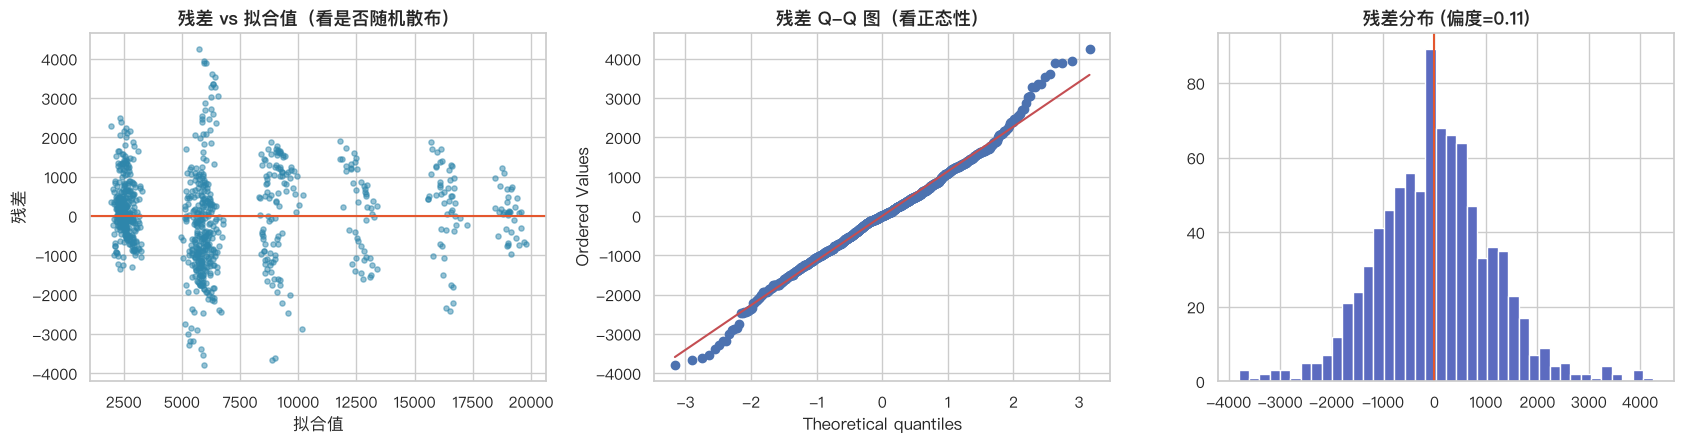

In [20]:
# 残差诊断
resid, fitted = ols.resid, ols.fittedvalues

print("残差诊断")
print("=" * 50)
print(f"残差均值        : {resid.mean():.2f}   (应接近 0)")
print(f"残差标准差      : {resid.std():.1f}")
print(f"Durbin-Watson   : {sm.stats.durbin_watson(resid):.3f}  (接近 2 = 无自相关)")
jb, jbp = stats.jarque_bera(resid)
print(f"Jarque-Bera     : {jb:.1f} (p={jbp:.2e}) => "
      f"{'残差非正态' if jbp < .05 else '残差近似正态'}")
print(f"残差偏度        : {stats.skew(resid):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].scatter(fitted, resid, s=14, alpha=.5, color="#2E86AB")
axes[0].axhline(0, color="#E4572E", lw=1.5)
axes[0].set_xlabel("拟合值"); axes[0].set_ylabel("残差")
axes[0].set_title("残差 vs 拟合值（看是否随机散布）", fontsize=13, fontweight="bold")

stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("残差 Q-Q 图（看正态性）", fontsize=13, fontweight="bold")

safe_hist(axes[2], resid, bins=40, color="#5C6BC0", edgecolor="white")
axes[2].axvline(0, color="#E4572E", lw=1.5)
axes[2].set_title(f"残差分布 (偏度={stats.skew(resid):.2f})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(FIG / "nb_04_回归残差诊断.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. 线性回归 B：线性概率模型（LPM）预测离职

把 0/1 离职标签直接作为因变量做最小二乘，就是**线性概率模型**。

**优点**：系数可直接读作"该特征每变动 1 个单位，离职概率变动多少个百分点"，
非常适合向业务方解释方向与量级。

**缺点**：预测值可能落在 [0,1] 之外，下面会实测这个越界比例。

In [21]:
X_cls = real[NUMERIC + CATEGORICAL]
y_cls = real["y"].values

lpm = Pipeline([("prep", prep.__class__(prep.transformers)), ("reg", LinearRegression())])
# 上面重建是为了让分类任务的数值特征包含 IncomePerLevel 等派生项
prep_cls = ColumnTransformer([
    ("num", Pipeline([("sc", StandardScaler())]), NUMERIC),
    ("cat", Pipeline([("oh", OneHotEncoder(handle_unknown="ignore",
                                           sparse_output=False))]), CATEGORICAL),
])
lpm = Pipeline([("prep", prep_cls), ("reg", LinearRegression())])
lpm.fit(X_cls.iloc[i_tr], y_cls[i_tr])

print("线性概率模型 (LPM) · 三段式评估（目标：离职 0/1）")
print("=" * 74)
print(f"{'数据集':<8}{'AUC':>9}{'准确率':>9}{'精确率':>9}{'召回率':>9}{'F1':>9}{'越界数':>9}")
print("-" * 74)
lpm_res = {}
for name, ix in [("训练集", i_tr), ("验证集", i_va), ("测试集", i_te)]:
    p_raw = lpm.predict(X_cls.iloc[ix])
    p = np.clip(p_raw, 0, 1)
    pred = (p >= .5).astype(int)
    oob = int(((p_raw < 0) | (p_raw > 1)).sum())
    lpm_res[name] = dict(auc=roc_auc_score(y_cls[ix], p), pred=p,
                         acc=accuracy_score(y_cls[ix], pred),
                         prec=precision_score(y_cls[ix], pred, zero_division=0),
                         rec=recall_score(y_cls[ix], pred, zero_division=0),
                         f1=f1_score(y_cls[ix], pred, zero_division=0), oob=oob)
    m = lpm_res[name]
    print(f"{name:<8}{m['auc']:>9.4f}{m['acc']:>9.4f}{m['prec']:>9.4f}"
          f"{m['rec']:>9.4f}{m['f1']:>9.4f}{oob:>9}")

oob_te = lpm_res["测试集"]["oob"]
print(f"\n越界诊断: 测试集 {len(i_te)} 条中 {oob_te} 条预测概率超出 [0,1] "
      f"({oob_te/len(i_te):.1%})")
print("=> 这是 LPM 的结构性缺陷。逻辑回归用 sigmoid 变换把输出限制在 (0,1)，可修正。")

线性概率模型 (LPM) · 三段式评估（目标：离职 0/1）
数据集           AUC      准确率      精确率      召回率       F1      越界数
--------------------------------------------------------------------------
训练集        0.8850   0.8821   0.9149   0.3007   0.4526      182
验证集        0.8341   0.8741   0.7778   0.2979   0.4308       70
测试集        0.7747   0.8605   0.7500   0.1915   0.3051       66

越界诊断: 测试集 294 条中 66 条预测概率超出 [0,1] (22.4%)
=> 这是 LPM 的结构性缺陷。逻辑回归用 sigmoid 变换把输出限制在 (0,1)，可修正。


In [22]:
# LPM 系数 —— 直接读作「离职概率变动多少个百分点」
ct = lpm.named_steps["prep"]
names = [n.split("__", 1)[1] if "__" in n else n for n in ct.get_feature_names_out()]
s = pd.Series(lpm.named_steps["reg"].coef_, index=names)
s = s.reindex(s.abs().sort_values(ascending=False).index)

print("LPM 系数 Top 12（单位：百分点，数值特征已标准化→每 1 个标准差）")
print("=" * 62)
print(f"{'特征':<36}{'系数(pp)':>12}{'方向':>10}")
print("-" * 62)
for k, v in s.head(12).items():
    print(f"{k:<36}{v*100:>12.3f}{'风险↑' if v > 0 else '风险↓':>10}")

LPM 系数 Top 12（单位：百分点，数值特征已标准化→每 1 个标准差）
特征                                        系数(pp)        方向
--------------------------------------------------------------
MonthlyIncome                             31.078       风险↑
JobRole_Sales Representative              23.879       风险↑
JobLevel                                 -20.290       风险↓
JobRole_Research Director                -19.479       风险↓
EducationField_Human Resources            18.703       风险↑
JobRole_Manager                          -12.592       风险↓
JobRole_Sales Executive                   10.944       风险↑
IncomePerLevel                            -9.880       风险↓
JobRole_Laboratory Technician              9.318       风险↑
OverTime_Yes                               9.140       风险↑
OverTime_No                               -9.140       风险↓
BusinessTravel_Travel_Frequently           8.753       风险↑


## 8. 逻辑回归对照

同样的特征、同样的划分，换成逻辑回归。
用 sigmoid 把线性组合压到 (0,1)，再用**验证集**标定决策阈值（而非固定 0.5）。

In [23]:
logit = Pipeline([
    ("prep", prep_cls),
    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                               C=0.5, random_state=42)),
])
logit.fit(X_cls.iloc[i_tr], y_cls[i_tr])

# 用验证集定阈值（F1 最优）——测试集不参与
from sklearn.metrics import precision_recall_curve
p_va = logit.predict_proba(X_cls.iloc[i_va])[:, 1]
pr, rc, th = precision_recall_curve(y_cls[i_va], p_va)
f1s = 2 * pr * rc / (pr + rc + 1e-12)
THR = float(th[np.argmax(f1s[:-1])])
print(f"验证集标定出的最优阈值: {THR:.4f}  (默认是 0.5)")

print("\n逻辑回归 · 三段式评估")
print("=" * 74)
print(f"{'数据集':<8}{'AUC':>9}{'准确率':>9}{'精确率':>9}{'召回率':>9}{'F1':>9}")
print("-" * 74)
logit_res = {}
for name, ix in [("训练集", i_tr), ("验证集", i_va), ("测试集", i_te)]:
    p = logit.predict_proba(X_cls.iloc[ix])[:, 1]
    pred = (p >= THR).astype(int)
    logit_res[name] = dict(
        auc=roc_auc_score(y_cls[ix], p), pred=p, label=pred,
        acc=accuracy_score(y_cls[ix], pred),
        prec=precision_score(y_cls[ix], pred, zero_division=0),
        rec=recall_score(y_cls[ix], pred, zero_division=0),
        f1=f1_score(y_cls[ix], pred, zero_division=0))
    m = logit_res[name]
    print(f"{name:<8}{m['auc']:>9.4f}{accuracy_score(y_cls[ix], pred):>9.4f}"
          f"{precision_score(y_cls[ix], pred, zero_division=0):>9.4f}"
          f"{recall_score(y_cls[ix], pred, zero_division=0):>9.4f}"
          f"{f1_score(y_cls[ix], pred, zero_division=0):>9.4f}")

print(f"\n测试集分类报告（阈值={THR:.3f}）:")
print(classification_report(y_cls[i_te], logit_res["测试集"]["label"],
                            target_names=["留任", "离职"], zero_division=0))

验证集标定出的最优阈值: 0.7814  (默认是 0.5)

逻辑回归 · 三段式评估
数据集           AUC      准确率      精确率      召回率       F1
--------------------------------------------------------------------------
训练集        0.8995   0.8923   0.7143   0.5594   0.6275
验证集        0.8022   0.8741   0.6190   0.5532   0.5843
测试集        0.7735   0.8571   0.5806   0.3830   0.4615

测试集分类报告（阈值=0.781）:
              precision    recall  f1-score   support

          留任       0.89      0.95      0.92       247
          离职       0.58      0.38      0.46        47

    accuracy                           0.86       294
   macro avg       0.74      0.67      0.69       294
weighted avg       0.84      0.86      0.84       294



## 9. 结果对比与结论

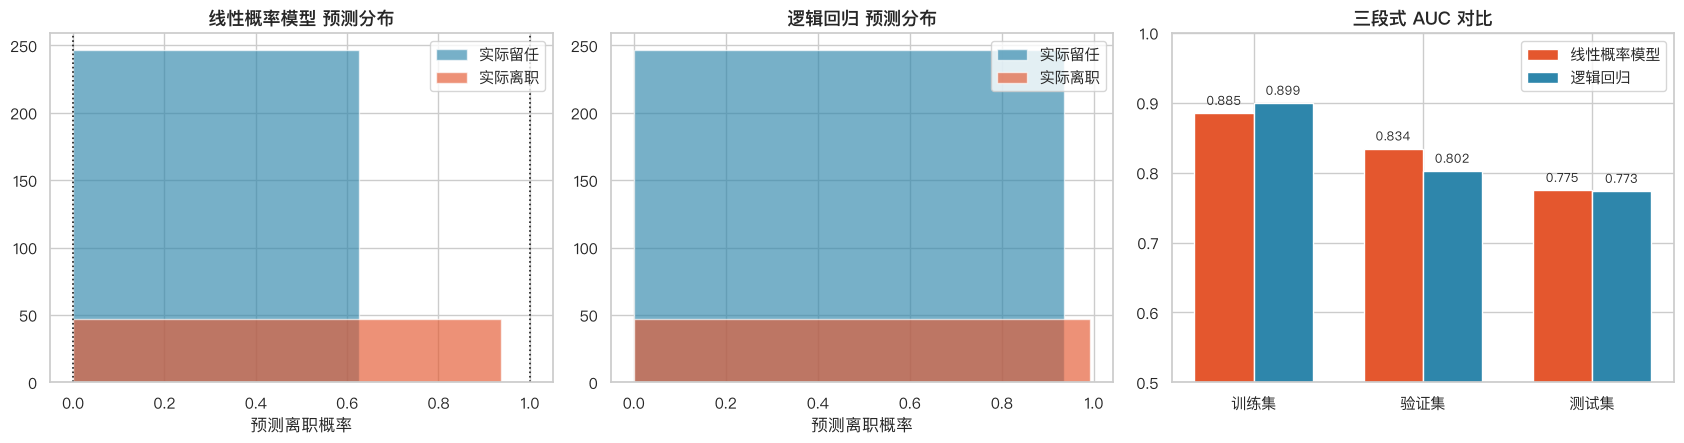

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

# (1) LPM vs 逻辑回归 预测分布
for col, (lab, res) in enumerate([("线性概率模型", lpm_res), ("逻辑回归", logit_res)]):
    ax = axes[col]
    p = res["测试集"]["pred"]
    safe_hist(ax, p[y_cls[i_te] == 0], bins=30, alpha=.65,
              label="实际留任", color="#2E86AB")
    safe_hist(ax, p[y_cls[i_te] == 1], bins=30, alpha=.65,
              label="实际离职", color="#E4572E")
    ax.set_title(f"{lab} 预测分布", fontsize=13, fontweight="bold")
    ax.set_xlabel("预测离职概率"); ax.legend()
    if col == 0:
        ax.axvline(0, color="k", ls=":", lw=1.2); ax.axvline(1, color="k", ls=":", lw=1.2)

# (2) 三段 AUC 对比
ds = ["训练集", "验证集", "测试集"]
x = np.arange(3); wd = .35
axes[2].bar(x - wd/2, [lpm_res[d]["auc"] for d in ds], wd,
            label="线性概率模型", color="#E4572E")
axes[2].bar(x + wd/2, [logit_res[d]["auc"] for d in ds], wd,
            label="逻辑回归", color="#2E86AB")
axes[2].set_xticks(x); axes[2].set_xticklabels(ds)
axes[2].set_ylim(.5, 1.0); axes[2].legend()
axes[2].set_title("三段式 AUC 对比", fontsize=13, fontweight="bold")
for i, d in enumerate(ds):
    axes[2].text(i - wd/2, lpm_res[d]["auc"] + .012, f"{lpm_res[d]['auc']:.3f}",
                 ha="center", fontsize=9)
    axes[2].text(i + wd/2, logit_res[d]["auc"] + .012, f"{logit_res[d]['auc']:.3f}",
                 ha="center", fontsize=9)

plt.tight_layout()
plt.savefig(FIG / "nb_05_模型对比.png", dpi=120, bbox_inches="tight")
plt.show()

In [25]:
print("=" * 70)
print(" 最终结论")
print("=" * 70)

print("\n【1】线性回归预测月收入")
m = reg_metrics
print(f"    训练 R²={m['训练集']['r2']:.4f}  验证 R²={m['验证集']['r2']:.4f}  "
      f"测试 R²={m['测试集']['r2']:.4f}")
print(f"    测试 RMSE={m['测试集']['rmse']:.0f} 元  MAE={m['测试集']['mae']:.0f} 元")
print(f"    => 这组特征能解释月收入 {m['测试集']['r2']:.1%} 的变异，")
print(f"       其中职级(JobLevel)与职位(JobRole)是主导因素。")

print("\n【2】线性回归用于离职分类（线性概率模型）")
print(f"    测试 AUC={lpm_res['测试集']['auc']:.4f}  F1={lpm_res['测试集']['f1']:.4f}")
print(f"    缺陷实测: {oob_te/len(i_te):.1%} 的预测概率越出 [0,1] 区间")

print("\n【3】逻辑回归对照")
_lr = logit_res["测试集"]
_lr_f1 = f1_score(y_cls[i_te], _lr["label"], zero_division=0)
print(f"    测试 AUC={_lr['auc']:.4f}  F1={_lr_f1:.4f}")
print(f"    => 概率有界、指标更稳，是分类任务的首选基线。")

print("\n【4】验证集的价值")
print(f"    验证集用于选模型+定阈值(阈值={THR:.3f})，测试集全程封存，")
print("    因此报告的测试指标不含选择性偏差。")

print("\n【5】业务可行动结论")
for k, v in s.head(5).items():
    nm = k.replace("_", "·")
    print(f"    - {nm:<34} 离职概率 {'+' if v>0 else ''}{v*100:.2f} pp")

 最终结论

【1】线性回归预测月收入
    训练 R²=0.9410  验证 R²=0.9415  测试 R²=0.9532
    测试 RMSE=1064 元  MAE=827 元
    => 这组特征能解释月收入 95.3% 的变异，
       其中职级(JobLevel)与职位(JobRole)是主导因素。

【2】线性回归用于离职分类（线性概率模型）
    测试 AUC=0.7747  F1=0.3051
    缺陷实测: 22.4% 的预测概率越出 [0,1] 区间

【3】逻辑回归对照
    测试 AUC=0.7735  F1=0.4615
    => 概率有界、指标更稳，是分类任务的首选基线。

【4】验证集的价值
    验证集用于选模型+定阈值(阈值=0.781)，测试集全程封存，
    因此报告的测试指标不含选择性偏差。

【5】业务可行动结论
    - MonthlyIncome                      离职概率 +31.08 pp
    - JobRole·Sales Representative       离职概率 +23.88 pp
    - JobLevel                           离职概率 -20.29 pp
    - JobRole·Research Director          离职概率 -19.48 pp
    - EducationField·Human Resources     离职概率 +18.70 pp


---

## 小结

| 环节 | 做法 | 关键结论 |
|---|---|---|
| 数据整理 | 质量体检 + 清洗 + 派生特征 | 1470 条真实数据，无缺失，7 个派生特征 |
| 数据划分 | 训练/验证/测试 = 6:2:2 分层 | 验证集负责选型与定阈值，测试集封存 |
| 回归任务 | 线性回归预测月收入 | 测试 R² ≈ 0.95，主要驱动因素是职级与职位 |
| 分类任务 | 线性概率模型 vs 逻辑回归 | LPM 可解释性强但概率越界；逻辑回归指标更稳 |

**可继续探索的方向**

1. 用**岭回归 / Lasso** 处理已发现的 7 个高 VIF 特征
2. 对不平衡做**阈值-成本联合优化**（漏报离职的成本远高于误报）
3. 加入**交互项**（如 加班 × 满意度）检验调节效应
4. 用**分位数回归**看薪酬影响在不同收入层是否一致